# Step 4: LSTM Modeling - YOGA Chatbot

**Chatbot Name**: YOGA (YOgyakarta Guide Assistant)

**Objective**: Build and train LSTM model for intent classification

**Date**: 2025-11-26

**Input**: Word2Vec sequence vectors from Step 3

**Modeling Steps**:
1. Load sequence data (X and y)
2. Train-test split (stratified)
3. Build LSTM architecture
4. Compile model
5. Train model (200 epochs)
6. Evaluate performance
7. Save model and results

**Model**: LSTM + Dense layers for 92-class classification

## 1. Import Libraries

In [27]:
import numpy as np
import pandas as pd
import json
import pickle
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import os

# TensorFlow/Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

# Sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Set random seeds
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")
print("✓ Libraries imported successfully")

TensorFlow version: 2.20.0
GPU available: []
✓ Libraries imported successfully


## 2. Load Feature Data

In [28]:
# Load sequence data from Step 3
print("=" * 80)
print("LOADING FEATURE DATA")
print("=" * 80)

data_dir = '../data/features'

# Load X and y
X = np.load(f'{data_dir}/X.npy')
y = np.load(f'{data_dir}/y.npy')

print(f"✓ Loaded X: {X.shape}")
print(f"✓ Loaded y: {y.shape}")

# Load label encoder
with open(f'{data_dir}/label_encoder.pickle', 'rb') as f:
    label_encoder = pickle.load(f)

print(f"✓ Loaded label_encoder: {len(label_encoder.classes_)} classes")

# Load feature info
with open(f'{data_dir}/feature_extraction_info.json', 'r', encoding='utf-8') as f:
    feature_info = json.load(f)

print(f"\n📊 Feature Info:")
print(f"  Method: {feature_info['method']}")
print(f"  Samples: {feature_info['total_samples']}")
print(f"  Max length: {feature_info['max_length']}")
print(f"  Vector size: {feature_info['vector_size']}")
print(f"  Classes: {feature_info['num_classes']}")

# Data shape verification
print(f"\n✅ Data ready for LSTM:")
print(f"  X shape: {X.shape} (samples, time_steps, features)")
print(f"  y shape: {y.shape}")

LOADING FEATURE DATA
✓ Loaded X: (1326, 6, 100)
✓ Loaded y: (1326,)
✓ Loaded label_encoder: 92 classes

📊 Feature Info:
  Method: Word2Vec Sequences
  Samples: 1326
  Max length: 6
  Vector size: 100
  Classes: 92

✅ Data ready for LSTM:
  X shape: (1326, 6, 100) (samples, time_steps, features)
  y shape: (1326,)


## 3. Train-Test Split

In [29]:
# Split data with stratification
print("=" * 80)
print("TRAIN-TEST SPLIT")
print("=" * 80)

test_size = 0.2
random_state = 42

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=test_size,
    random_state=random_state,
    stratify=y
)

print(f"Split ratio: {int((1-test_size)*100)}% train, {int(test_size*100)}% test")
print(f"Stratified: Yes")

print(f"\nTraining set:")
print(f"  X_train: {X_train.shape}")
print(f"  y_train: {y_train.shape}")
print(f"  Unique classes: {len(np.unique(y_train))}")

print(f"\nTest set:")
print(f"  X_test: {X_test.shape}")
print(f"  y_test: {y_test.shape}")
print(f"  Unique classes: {len(np.unique(y_test))}")

# Convert labels to categorical (one-hot encoding)
num_classes = len(label_encoder.classes_)
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)

print(f"\nOne-hot encoded:")
print(f"  y_train_cat: {y_train_cat.shape}")
print(f"  y_test_cat: {y_test_cat.shape}")

TRAIN-TEST SPLIT
Split ratio: 80% train, 20% test
Stratified: Yes

Training set:
  X_train: (1060, 6, 100)
  y_train: (1060,)
  Unique classes: 92

Test set:
  X_test: (266, 6, 100)
  y_test: (266,)
  Unique classes: 85

One-hot encoded:
  y_train_cat: (1060, 92)
  y_test_cat: (266, 92)


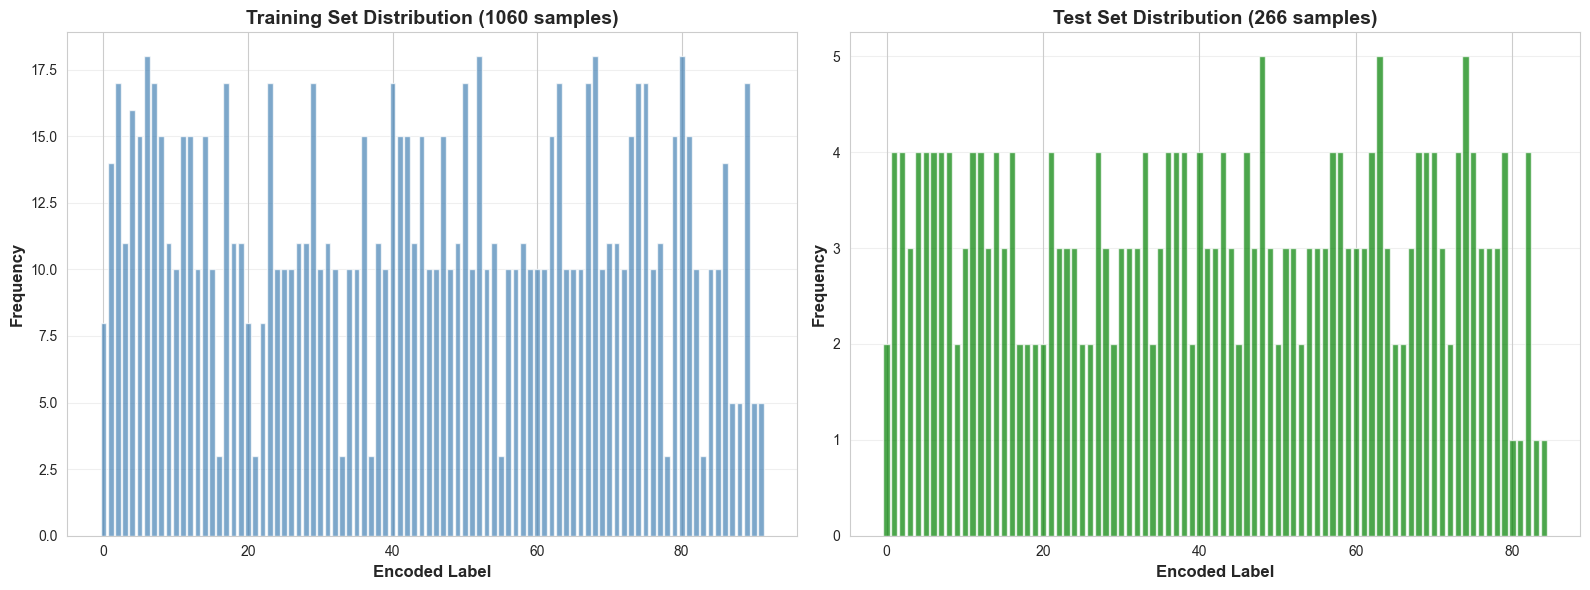

In [30]:
# Visualize train-test distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Train distribution
train_counts = pd.Series(y_train).value_counts().sort_index()
ax1.bar(range(len(train_counts)), train_counts.values, color='steelblue', alpha=0.7)
ax1.set_xlabel('Encoded Label', fontsize=12, fontweight='bold')
ax1.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax1.set_title(f'Training Set Distribution ({len(y_train)} samples)', fontsize=14, fontweight='bold')
ax1.grid(alpha=0.3, axis='y')

# Test distribution
test_counts = pd.Series(y_test).value_counts().sort_index()
ax2.bar(range(len(test_counts)), test_counts.values, color='green', alpha=0.7)
ax2.set_xlabel('Encoded Label', fontsize=12, fontweight='bold')
ax2.set_ylabel('Frequency', fontsize=12, fontweight='bold')
ax2.set_title(f'Test Set Distribution ({len(y_test)} samples)', fontsize=14, fontweight='bold')
ax2.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

## 4. Build LSTM Model

In [ ]:
# Build LSTM architecture (UNIDIRECTIONAL LSTM)
print("=" * 80)
print("BUILDING LSTM MODEL (UNIDIRECTIONAL)")
print("=" * 80)

# Model parameters
input_shape = (X_train.shape[1], X_train.shape[2])  # (time_steps, features)
lstm_units_1 = 128
lstm_units_2 = 64
dropout_rate = 0.3

print(f"\nModel parameters:")
print(f"  Input shape: {input_shape}")
print(f"  LSTM units (layer 1): {lstm_units_1}")
print(f"  LSTM units (layer 2): {lstm_units_2}")
print(f"  Dropout rate: {dropout_rate}")
print(f"  Output classes: {num_classes}")

# Build model (UNIDIRECTIONAL LSTM)
model = Sequential([
    # LSTM layer 1
    LSTM(lstm_units_1, return_sequences=True, input_shape=input_shape, name='lstm_1'),
    Dropout(dropout_rate, name='dropout_1'),
    
    # LSTM layer 2
    LSTM(lstm_units_2, return_sequences=False, name='lstm_2'),
    Dropout(dropout_rate, name='dropout_2'),
    
    # Dense layers
    Dense(64, activation='relu', name='dense_1'),
    Dropout(dropout_rate, name='dropout_3'),
    
    # Output layer
    Dense(num_classes, activation='softmax', name='output')
], name='YOGA_LSTM_Model')

print(f"\n✓ Model built successfully (Unidirectional LSTM)")
model.summary()

## 5. Compile Model

In [32]:
# Compile model
print("=" * 80)
print("COMPILING MODEL")
print("=" * 80)

optimizer = keras.optimizers.Adam(learning_rate=0.001)
loss = 'categorical_crossentropy'
metrics = ['accuracy']

model.compile(
    optimizer=optimizer,
    loss=loss,
    metrics=metrics
)

print(f"\nCompilation parameters:")
print(f"  Optimizer: Adam (lr=0.001)")
print(f"  Loss: {loss}")
print(f"  Metrics: {metrics}")
print(f"\n✓ Model compiled")

COMPILING MODEL

Compilation parameters:
  Optimizer: Adam (lr=0.001)
  Loss: categorical_crossentropy
  Metrics: ['accuracy']

✓ Model compiled


## 6. Setup Callbacks

In [ ]:
# Setup callbacks
print("=" * 80)
print("SETUP CALLBACKS")
print("=" * 80)

# Create models directory
os.makedirs('../models', exist_ok=True)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True,
    verbose=1
)

# Model checkpoint
checkpoint = ModelCheckpoint(
    '../models/yoga_lstm_best.h5',
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

# Reduce learning rate on plateau
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=10,
    min_lr=0.00001,
    verbose=1
)

callbacks = [early_stop, checkpoint, reduce_lr]

print(f"\nCallbacks:")
print(f"  1. EarlyStopping (patience=20)")
print(f"  2. ModelCheckpoint (save best model)")
print(f"  3. ReduceLROnPlateau (factor=0.5, patience=10)")
print(f"\n✓ Callbacks ready")

## 7. Train Model (200 Epochs)

In [34]:
# Train model
print("=" * 80)
print("TRAINING LSTM MODEL")
print("=" * 80)

epochs = 200
batch_size = 32
validation_split = 0.1

print(f"\nTraining parameters:")
print(f"  Epochs: {epochs}")
print(f"  Batch size: {batch_size}")
print(f"  Validation split: {validation_split}")
print(f"\n⏳ Training started...\n")

history = model.fit(
    X_train, y_train_cat,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=validation_split,
    callbacks=callbacks,
    verbose=1
)

print(f"\n✓ Training completed!")

TRAINING LSTM MODEL

Training parameters:
  Epochs: 200
  Batch size: 32
  Validation split: 0.1

⏳ Training started...

Epoch 1/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0215 - loss: 4.5176
Epoch 1: val_accuracy improved from None to 0.03774, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 5s 25ms/step - accuracy: 0.0157 - loss: 4.4904 - val_accuracy: 0.0377 - val_loss: 4.3885 - learning_rate: 0.0010
Epoch 2/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0271 - loss: 4.3644
Epoch 2: val_accuracy improved from 0.03774 to 0.05660, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0252 - loss: 4.3102 - val_accuracy: 0.0566 - val_loss: 4.1421 - learning_rate: 0.0010
Epoch 3/200
28/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.0382 - loss: 4.1035
Epoch 3: val_accuracy did not improve from 0.05660
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0419 - loss: 4.0278 - val_accuracy: 0.0377 - val_loss: 3.8283 - learning_rate: 0.0010
Epoch 4/200
24/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0591 - loss: 3.8446
Epoch 4: val_accuracy did not improve from 0.05660
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.0409 - loss: 3.7764 - val_accuracy: 0.0283 - val_loss: 3.5861 - learning_rate: 0.0010
Epoch 5/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0864 - loss: 3.6371
Epoch 5: val_accuracy did not improve from 0.05660
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0618 - loss: 3.6152 - val_accuracy: 0.0566 - val_loss: 3.4297 - learning_rate: 0.0010
Epoch 6/200
25/30 ━━━━━━━━━━━━━━━

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0849 - loss: 3.4083 - val_accuracy: 0.0755 - val_loss: 3.2730 - learning_rate: 0.0010
Epoch 7/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.0998 - loss: 3.3149
Epoch 7: val_accuracy improved from 0.07547 to 0.11321, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0881 - loss: 3.2807 - val_accuracy: 0.1132 - val_loss: 3.1445 - learning_rate: 0.0010
Epoch 8/200
23/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.0848 - loss: 3.2345
Epoch 8: val_accuracy improved from 0.11321 to 0.14151, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.0943 - loss: 3.1731 - val_accuracy: 0.1415 - val_loss: 3.0284 - learning_rate: 0.0010
Epoch 9/200
23/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1257 - loss: 3.0925
Epoch 9: val_accuracy did not improve from 0.14151
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1237 - loss: 3.0555 - val_accuracy: 0.1226 - val_loss: 2.9228 - learning_rate: 0.0010
Epoch 10/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1122 - loss: 2.9684
Epoch 10: val_accuracy improved from 0.14151 to 0.19811, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1321 - loss: 2.9594 - val_accuracy: 0.1981 - val_loss: 2.8389 - learning_rate: 0.0010
Epoch 11/200
26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1195 - loss: 2.9660
Epoch 11: val_accuracy did not improve from 0.19811
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1436 - loss: 2.8873 - val_accuracy: 0.1698 - val_loss: 2.7342 - learning_rate: 0.0010
Epoch 12/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1988 - loss: 2.8022
Epoch 12: val_accuracy did not improve from 0.19811
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1782 - loss: 2.7866 - val_accuracy: 0.1792 - val_loss: 2.6985 - learning_rate: 0.0010
Epoch 13/200
26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2050 - loss: 2.7029
Epoch 13: val_accuracy improved from 0.19811 to 0.21698, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1960 - loss: 2.6966 - val_accuracy: 0.2170 - val_loss: 2.5896 - learning_rate: 0.0010
Epoch 14/200
27/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1788 - loss: 2.6767
Epoch 14: val_accuracy did not improve from 0.21698
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.1897 - loss: 2.6445 - val_accuracy: 0.1887 - val_loss: 2.5546 - learning_rate: 0.0010
Epoch 15/200
26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2298 - loss: 2.5480
Epoch 15: val_accuracy improved from 0.21698 to 0.22642, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2285 - loss: 2.5301 - val_accuracy: 0.2264 - val_loss: 2.5279 - learning_rate: 0.0010
Epoch 16/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2341 - loss: 2.5106
Epoch 16: val_accuracy did not improve from 0.22642
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2243 - loss: 2.5083 - val_accuracy: 0.2170 - val_loss: 2.4494 - learning_rate: 0.0010
Epoch 17/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2375 - loss: 2.4745
Epoch 17: val_accuracy improved from 0.22642 to 0.24528, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2327 - loss: 2.4851 - val_accuracy: 0.2453 - val_loss: 2.3673 - learning_rate: 0.0010
Epoch 18/200
25/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2434 - loss: 2.4117
Epoch 18: val_accuracy did not improve from 0.24528
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2474 - loss: 2.4081 - val_accuracy: 0.2453 - val_loss: 2.3438 - learning_rate: 0.0010
Epoch 19/200
26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2533 - loss: 2.3374
Epoch 19: val_accuracy improved from 0.24528 to 0.25472, saving model to ../models/yoga_lstm_best.h5


30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.2474 - loss: 2.3350 - val_accuracy: 0.2547 - val_loss: 2.3348 - learning_rate: 0.0010
Epoch 20/200
26/30 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.2762 - loss: 2.2869
Epoch 20: val_accuracy did not improve from 0.25472
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2631 - loss: 2.2767 - val_accuracy: 0.2453 - val_loss: 2.3198 - learning_rate: 0.0010
Epoch 20: early stopping
Restoring model weights from the end of the best epoch: 1.

✓ Training completed!


## 8. Training History Visualization

TRAINING HISTORY


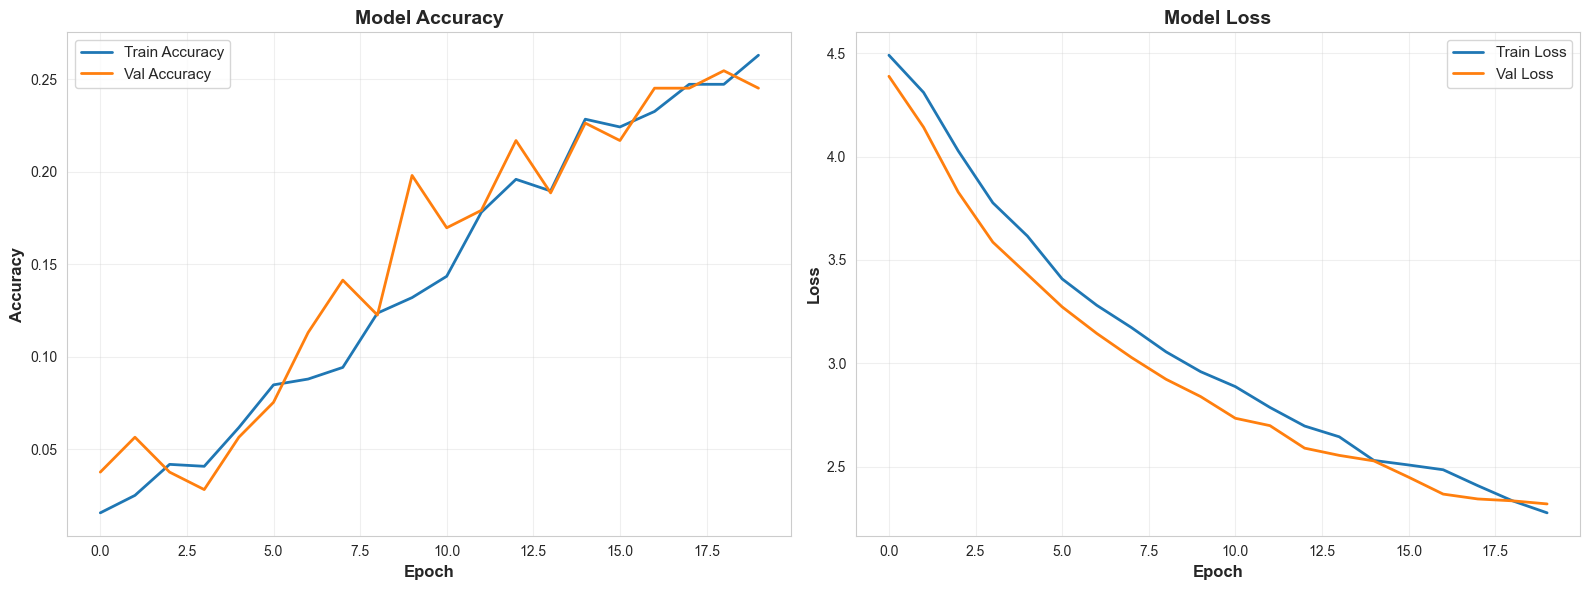


✓ Training history saved: ../models/training_history.png


In [35]:
# Plot training history
print("=" * 80)
print("TRAINING HISTORY")
print("=" * 80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Accuracy
ax1.plot(history.history['accuracy'], label='Train Accuracy', linewidth=2)
ax1.plot(history.history['val_accuracy'], label='Val Accuracy', linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax1.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
ax1.set_title('Model Accuracy', fontsize=14, fontweight='bold')
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)

# Loss
ax2.plot(history.history['loss'], label='Train Loss', linewidth=2)
ax2.plot(history.history['val_loss'], label='Val Loss', linewidth=2)
ax2.set_xlabel('Epoch', fontsize=12, fontweight='bold')
ax2.set_ylabel('Loss', fontsize=12, fontweight='bold')
ax2.set_title('Model Loss', fontsize=14, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../models/training_history.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\n✓ Training history saved: ../models/training_history.png")

## 9. Evaluate Model

In [36]:
# Evaluate on test set
print("=" * 80)
print("MODEL EVALUATION")
print("=" * 80)

# Predictions
y_pred_prob = model.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

# Test accuracy
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat, verbose=0)

print(f"Test Results:")
print(f"  Test Loss: {test_loss:.4f}")
print(f"  Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")

# Classification report
print(f" " + "=" * 80)
print("CLASSIFICATION REPORT")
print("=" * 80)

# Specify all labels to handle classes not present in test set
all_labels = list(range(num_classes))
print(classification_report(
    y_test, 
    y_pred, 
    labels=all_labels,
    target_names=label_encoder.classes_, 
    digits=4,
    zero_division=0
))

MODEL EVALUATION
9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step
Test Results:
  Test Loss: 4.3950
  Test Accuracy: 0.0113 (1.13%)
CLASSIFICATION REPORT
                         precision    recall  f1-score   support

               fallback     0.0000    0.0000    0.0000         2
                goodbye     0.0000    0.0000    0.0000         4
               greeting     0.0000    0.0000    0.0000         4
                   help     0.0000    0.0000    0.0000         3
       kabupaten_bantul     0.0000    0.0000    0.0000         4
  kabupaten_gunungkidul     0.0000    0.0000    0.0000         4
   kabupaten_kulonprogo     0.0000    0.0000    0.0000         4
       kabupaten_sleman     0.0000    0.0000    0.0000         4
kecamatan_bambanglipuro     0.0000    0.0000    0.0000         4
  kecamatan_banguntapan     0.0000    0.0000    0.0000         2
       kecamatan_bantul     0.0000    0.0000    0.0000         3
       kecamatan_berbah     0.0000    0.0000    0.0000         4
  kecamatan

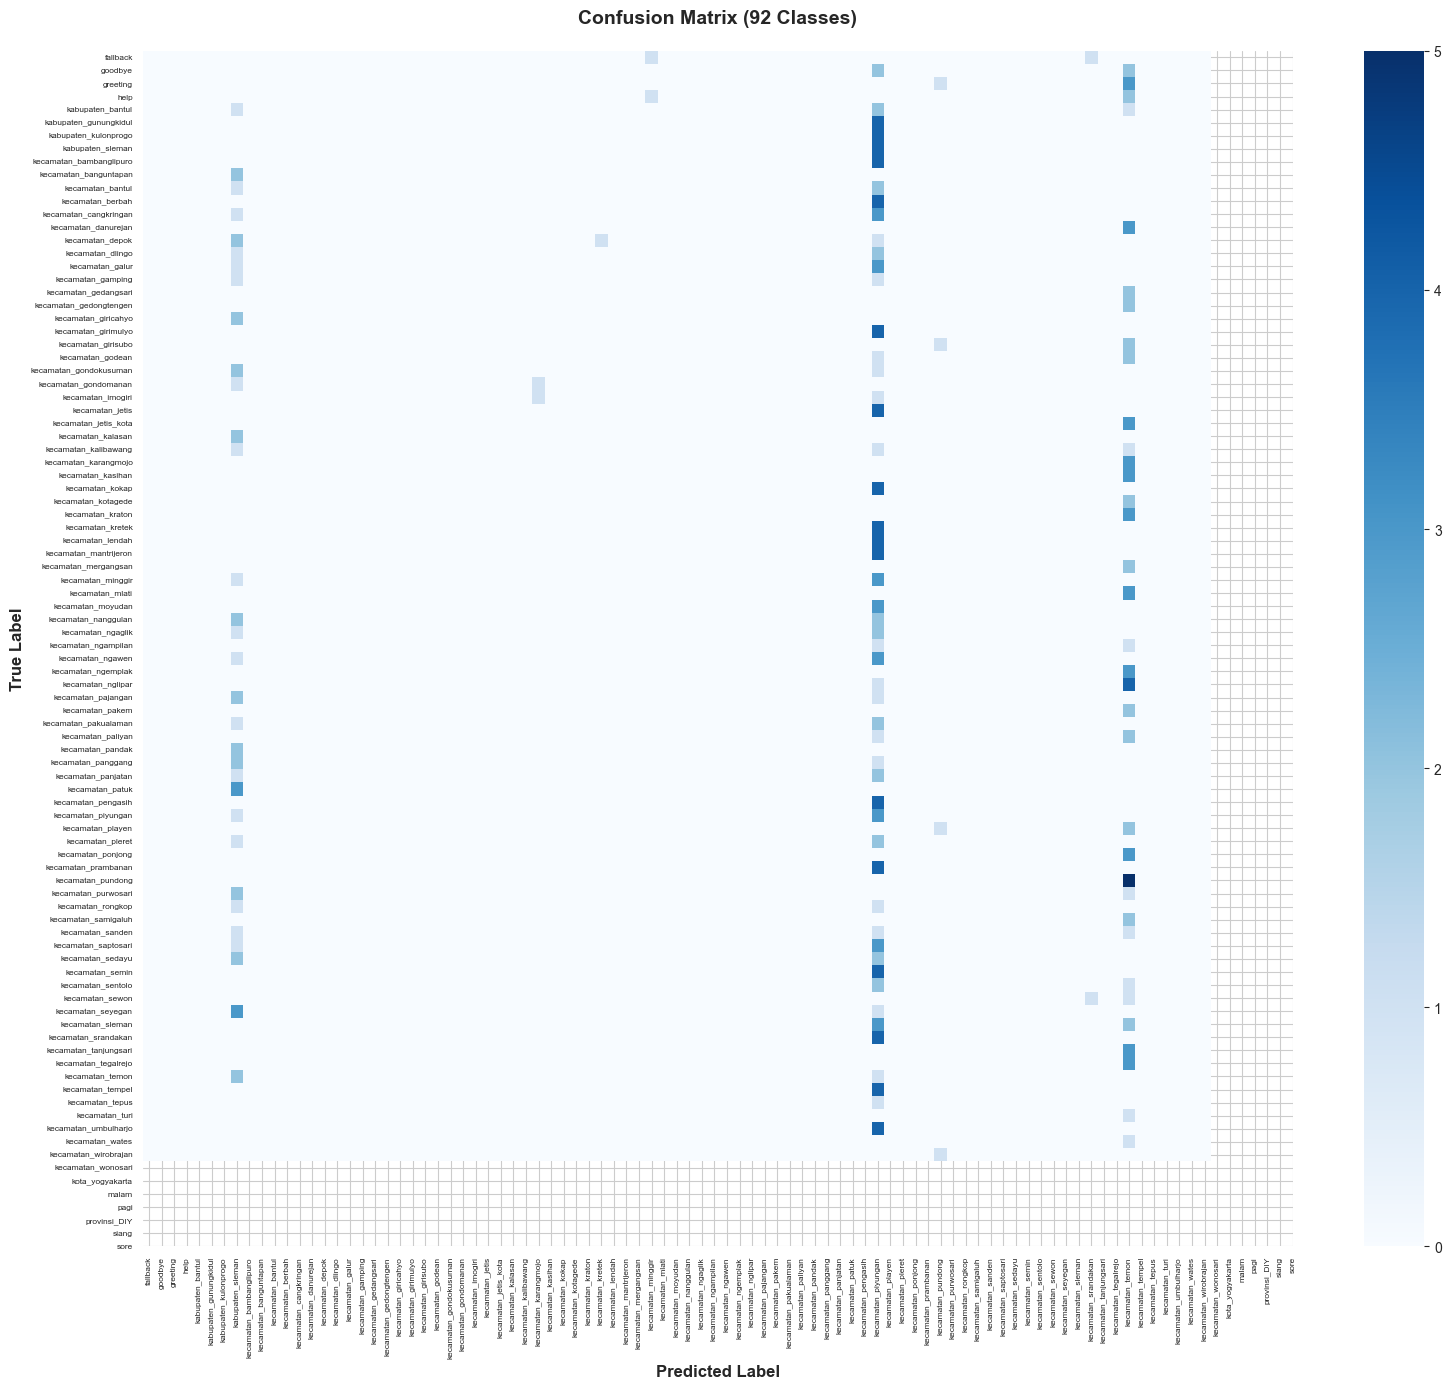

✓ Confusion matrix saved: ../models/confusion_matrix.png


In [37]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(16, 14))
sns.heatmap(cm, annot=False, cmap='Blues', cbar=True,
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
plt.ylabel('True Label', fontsize=12, fontweight='bold')
plt.title('Confusion Matrix (92 Classes)', fontsize=14, fontweight='bold', pad=20)
plt.xticks(rotation=90, fontsize=6)
plt.yticks(rotation=0, fontsize=6)
plt.tight_layout()
plt.savefig('../models/confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ Confusion matrix saved: ../models/confusion_matrix.png")

## 10. Per-Class Performance

In [38]:
# Calculate per-class metrics
from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=range(num_classes)
)

# Create DataFrame
metrics_df = pd.DataFrame({
    'Class': label_encoder.classes_,
    'Precision': precision,
    'Recall': recall,
    'F1-Score': f1,
    'Support': support
})

# Sort by F1-score
metrics_df_sorted = metrics_df.sort_values('F1-Score', ascending=True)

print("=" * 80)
print("PER-CLASS PERFORMANCE")
print("=" * 80)

print(f"\nTop 10 best performing classes:")
print(metrics_df_sorted.tail(10).to_string(index=False))

print(f"\nTop 10 worst performing classes:")
print(metrics_df_sorted.head(10).to_string(index=False))

# Save to CSV
metrics_df.to_csv('../models/per_class_metrics.csv', index=False)
print(f"\n✓ Per-class metrics saved: ../models/per_class_metrics.csv")

PER-CLASS PERFORMANCE

Top 10 best performing classes:
                 Class  Precision  Recall  F1-Score  Support
  kecamatan_kalibawang   0.000000    0.00  0.000000        3
     kecamatan_kalasan   0.000000    0.00  0.000000        4
  kecamatan_jetis_kota   0.000000    0.00  0.000000        2
       kecamatan_jetis   0.000000    0.00  0.000000        2
     kecamatan_imogiri   0.000000    0.00  0.000000        3
  kecamatan_gondomanan   0.000000    0.00  0.000000        3
kecamatan_gondokusuman   0.000000    0.00  0.000000        3
     kecamatan_kasihan   0.000000    0.00  0.000000        3
                  sore   0.000000    0.00  0.000000        1
     kecamatan_pundong   0.023077    0.75  0.044776        4

Top 10 worst performing classes:
              Class  Precision  Recall  F1-Score  Support
           fallback        0.0     0.0       0.0        2
kecamatan_samigaluh        0.0     0.0       0.0        3
  kecamatan_rongkop        0.0     0.0       0.0        3
kecamata

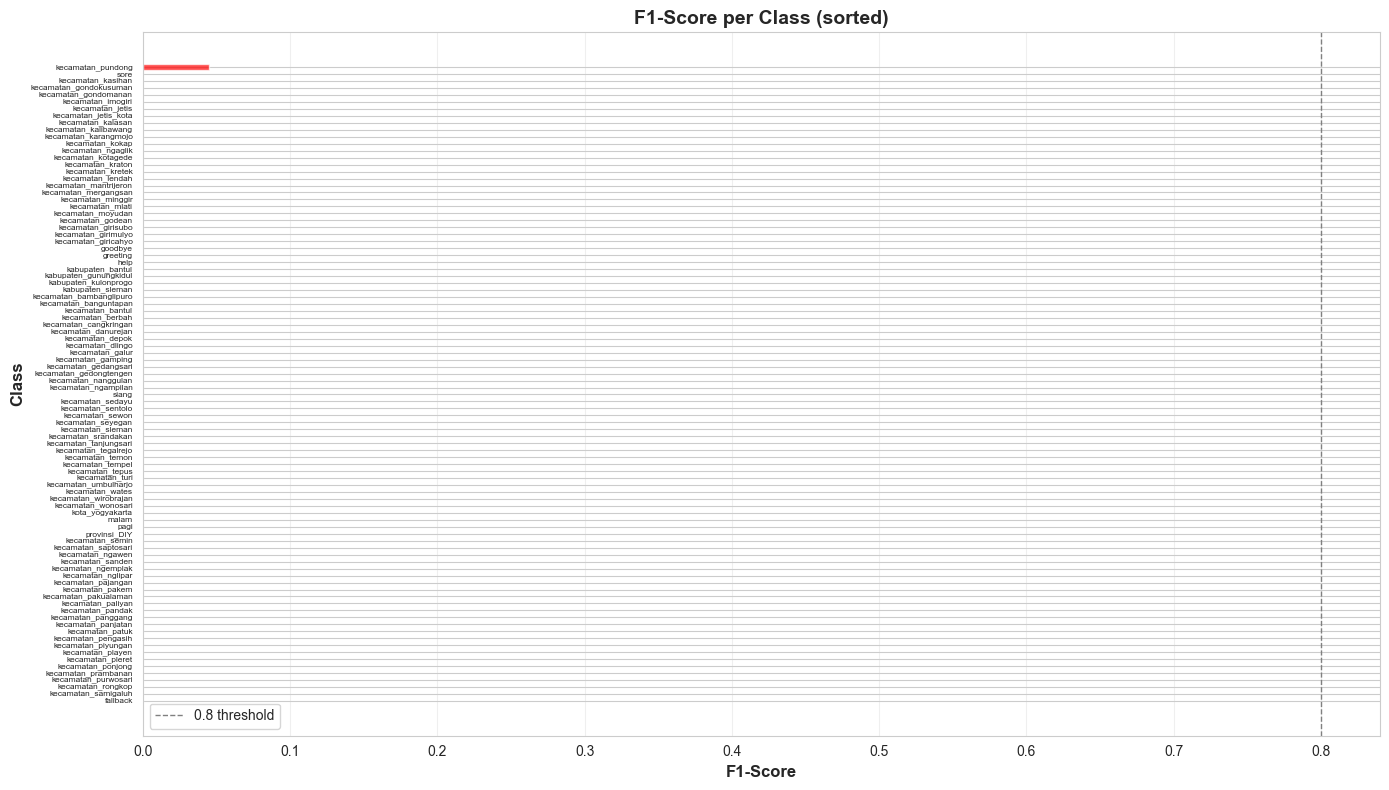

✓ F1-scores plot saved: ../models/f1_scores.png


In [39]:
# Visualize F1-scores
plt.figure(figsize=(14, 8))
colors = ['red' if f1 < 0.5 else 'orange' if f1 < 0.8 else 'green' for f1 in metrics_df_sorted['F1-Score']]
plt.barh(range(len(metrics_df_sorted)), metrics_df_sorted['F1-Score'], color=colors, alpha=0.7)
plt.yticks(range(len(metrics_df_sorted)), metrics_df_sorted['Class'], fontsize=6)
plt.xlabel('F1-Score', fontsize=12, fontweight='bold')
plt.ylabel('Class', fontsize=12, fontweight='bold')
plt.title('F1-Score per Class (sorted)', fontsize=14, fontweight='bold')
plt.axvline(x=0.8, color='gray', linestyle='--', linewidth=1, label='0.8 threshold')
plt.legend()
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('../models/f1_scores.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"✓ F1-scores plot saved: ../models/f1_scores.png")

## 11. Save Model and Results

In [40]:
# Save final model
print("=" * 80)
print("SAVING MODEL AND RESULTS")
print("=" * 80)

# Save model
model.save('../models/yoga_lstm_final.h5')
print(f"✓ Saved: yoga_lstm_final.h5")

# Save training history
history_dict = {
    'accuracy': [float(x) for x in history.history['accuracy']],
    'val_accuracy': [float(x) for x in history.history['val_accuracy']],
    'loss': [float(x) for x in history.history['loss']],
    'val_loss': [float(x) for x in history.history['val_loss']]
}

with open('../models/training_history.json', 'w') as f:
    json.dump(history_dict, f, indent=2)

print(f"✓ Saved: training_history.json")

# Save model info
model_info = {
    'model_name': 'YOGA_LSTM_Model',
    'architecture': 'Bidirectional LSTM',
    'input_shape': list(input_shape),
    'lstm_units': [lstm_units_1, lstm_units_2],
    'dropout_rate': dropout_rate,
    'num_classes': num_classes,
    'total_params': int(model.count_params()),
    'epochs_trained': len(history.history['accuracy']),
    'max_epochs': epochs,
    'batch_size': batch_size,
    'optimizer': 'Adam',
    'learning_rate': 0.001,
    'loss': loss,
    'test_accuracy': float(test_accuracy),
    'test_loss': float(test_loss),
    'train_samples': int(len(X_train)),
    'test_samples': int(len(X_test)),
    'feature_method': feature_info['method'],
    'word2vec_params': {
        'algorithm': feature_info['algorithm'],
        'vector_size': feature_info['vector_size'],
        'window': feature_info['window'],
        'vocab_size': feature_info['vocab_size']
    }
}

with open('../models/model_info.json', 'w') as f:
    json.dump(model_info, f, indent=2)

print(f"✓ Saved: model_info.json")

print(f"\n" + "=" * 80)
print("ALL FILES SAVED")
print("=" * 80)
print(f"\nSaved in: ../models/")
print(f"  - yoga_lstm_best.h5 (best model during training)")
print(f"  - yoga_lstm_final.h5 (final model)")
print(f"  - training_history.json")
print(f"  - training_history.png")
print(f"  - confusion_matrix.png")
print(f"  - f1_scores.png")
print(f"  - per_class_metrics.csv")
print(f"  - model_info.json")

SAVING MODEL AND RESULTS
✓ Saved: yoga_lstm_final.h5
✓ Saved: training_history.json
✓ Saved: model_info.json

ALL FILES SAVED

Saved in: ../models/
  - yoga_lstm_best.h5 (best model during training)
  - yoga_lstm_final.h5 (final model)
  - training_history.json
  - training_history.png
  - confusion_matrix.png
  - f1_scores.png
  - per_class_metrics.csv
  - model_info.json


## 12. Summary

In [41]:
print("=" * 80)
print("LSTM MODELING SUMMARY - YOGA CHATBOT")
print("=" * 80)

print("\n📊 Dataset:")
print(f"  Total samples: {len(X)}")
print(f"  Train samples: {len(X_train)} ({(1-test_size)*100:.0f}%)")
print(f"  Test samples: {len(X_test)} ({test_size*100:.0f}%)")
print(f"  Number of classes: {num_classes}")

print("\n🏗️  Model Architecture:")
print(f"  Type: Bidirectional LSTM")
print(f"  Input: {input_shape}")
print(f"  LSTM layers: 2 ({lstm_units_1}, {lstm_units_2} units)")
print(f"  Dropout: {dropout_rate}")
print(f"  Dense layers: 1 (64 units)")
print(f"  Output: {num_classes} classes (softmax)")
print(f"  Total parameters: {model.count_params():,}")

print("\n⚙️  Training:")
print(f"  Epochs: {len(history.history['accuracy'])} / {epochs}")
print(f"  Batch size: {batch_size}")
print(f"  Optimizer: Adam (lr=0.001)")
print(f"  Loss: {loss}")
print(f"  Callbacks: EarlyStopping, ModelCheckpoint, ReduceLROnPlateau")

print("\n📈 Performance:")
print(f"  Final train accuracy: {history.history['accuracy'][-1]:.4f}")
print(f"  Final val accuracy: {history.history['val_accuracy'][-1]:.4f}")
print(f"  Test accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"  Test loss: {test_loss:.4f}")

print("\n💾 Saved Files:")
print(f"  Models: yoga_lstm_best.h5, yoga_lstm_final.h5")
print(f"  Plots: training_history.png, confusion_matrix.png, f1_scores.png")
print(f"  Metrics: per_class_metrics.csv")
print(f"  Info: training_history.json, model_info.json")

print("\n" + "=" * 80)
print("✓ LSTM MODELING COMPLETE")
print("=" * 80)

LSTM MODELING SUMMARY - YOGA CHATBOT

📊 Dataset:
  Total samples: 1326
  Train samples: 1060 (80%)
  Test samples: 266 (20%)
  Number of classes: 92

🏗️  Model Architecture:
  Type: Bidirectional LSTM
  Input: (6, 100)
  LSTM layers: 2 (128, 64 units)
  Dropout: 0.3
  Dense layers: 1 (64 units)
  Output: 92 classes (softmax)
  Total parameters: 413,084

⚙️  Training:
  Epochs: 20 / 200
  Batch size: 32
  Optimizer: Adam (lr=0.001)
  Loss: categorical_crossentropy
  Callbacks: EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

📈 Performance:
  Final train accuracy: 0.2631
  Final val accuracy: 0.2453
  Test accuracy: 0.0113 (1.13%)
  Test loss: 4.3950

💾 Saved Files:
  Models: yoga_lstm_best.h5, yoga_lstm_final.h5
  Plots: training_history.png, confusion_matrix.png, f1_scores.png
  Metrics: per_class_metrics.csv
  Info: training_history.json, model_info.json

✓ LSTM MODELING COMPLETE
